# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

  


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")
penguins = sns.load_dataset("penguins")

In [3]:
class DataAnalyzer:

    def __init__(self, data, name = 'Dataset'):
        self.data = data
        self.name = name

        #Remembers which columns are numerical or categorical
        self.numerical_col = data.select_dtypes(include="number").columns.tolist()
        self.categorical_col = data.select_dtypes(exclude="number").columns.tolist()

        #Shape and column names
        print(f"Shape: {self.data.shape}  ({self.data.shape[0]} rows, {self.data.shape[1]} columns)")
        print(f"Column names: {self.data.columns.tolist()}")

    def plot_numeric(self, col):
        # Histogram with KDE curve (shape) next to a boxplot (spread and outliers).
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        sns.histplot(self.data[col], kde=True, ax=axes[0])
        axes[0].set_title(f"Distribution of {col}")
        sns.boxplot(x=self.data[col], ax=axes[1])
        axes[1].set_title(f"Boxplot of {col}")
        plt.tight_layout()
        plt.show()

    def plot_categorical(self, col):
        # Show counts/percentages for one categorical column and a bar chart of the counts.
        counts = self.data[col].value_counts()
        percent = (self.data[col].value_counts(normalize=True) * 100).round(1)
        print(pd.DataFrame({"count": counts, "percent": percent}))

        plt.figure(figsize=(6, 4))
        sns.countplot(data=self.data, x=col, order=counts.index)
        plt.title(f"Count of {col}")
        plt.show()

    def categorical_vs_categorical(self, a, b):
        # Crosstab, stacked bar chart, test of independence.
        table = pd.crosstab(self.data[a], self.data[b])
        print(table)
        
        # Each bar shows the share of each level of b within a
        table.div(table.sum(axis=1), axis=0).plot(kind="bar", stacked=True, figsize=(7, 4))
        plt.title(f"{b} share within each {a}")
        plt.ylabel("Proportion")
        plt.xticks(rotation=0)
        plt.show()

    def numeric_vs_numeric(self, x, y, hue=None):
        # Scatter plot and p-value for two numeric columns.
        clean = self.data[[x, y]].dropna()

        plt.figure(figsize=(6, 5))
        sns.scatterplot(data=self.data, x=x, y=y, hue=hue)   # hue colors points by a category
        plt.title(f"{y} vs. {x}")
        plt.show()

    def numeric_by_category(self, num, cat):
        # Group statistics and boxplot of a numeric column across the levels of a category.
        print(self.data.groupby(cat)[num].agg(["count", "mean", "median", "std"]).round(2))

        plt.figure(figsize=(7, 4))
        sns.boxplot(data=self.data, x=cat, y=num)
        plt.title(f"{num} by {cat}")
        plt.show()

In [4]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [5]:
penguinsData = DataAnalyzer(penguins, name="Penguins")
print(penguinsData)

Shape: (344, 7)  (344 rows, 7 columns)
Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


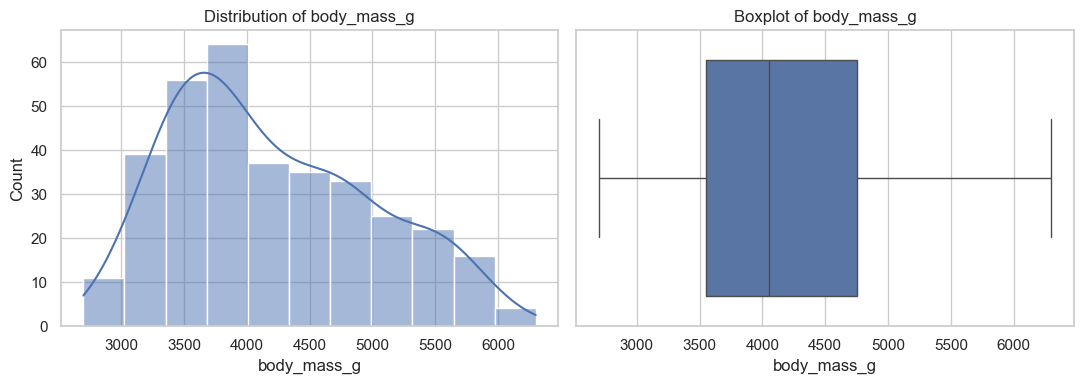

In [6]:
penguinsData.plot_numeric("body_mass_g")
# In this analysis I want to see the probability density of all penguin specie's body mass

        count  percent
sex                   
Male      168     50.5
Female    165     49.5


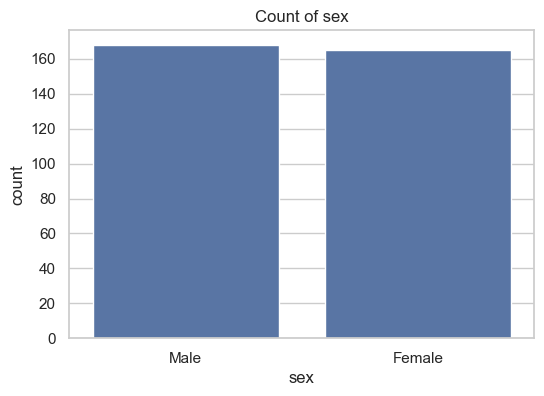

In [7]:
penguinsData.plot_categorical('sex')
# In this analysis I want to see if there is a disparity between the two sexes in all penguin species

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0


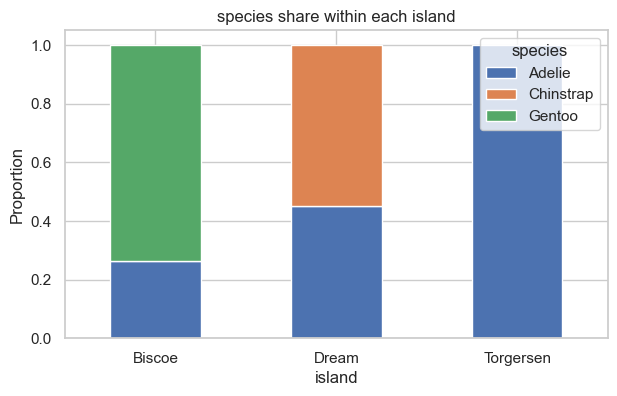

In [8]:
penguinsData.categorical_vs_categorical("island", "species")
# In this analysis I want to see which island holds how much of each species (if any)

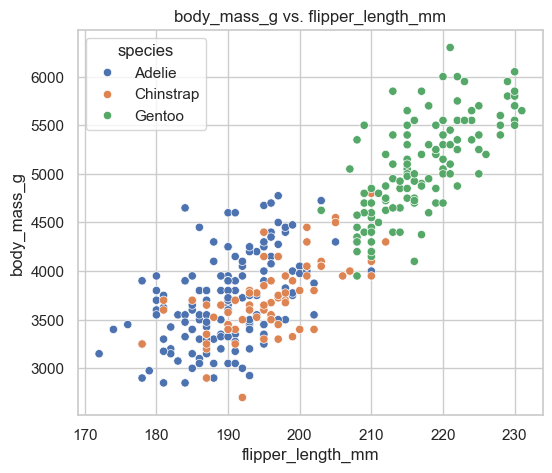

In [9]:
penguinsData.numeric_vs_numeric("flipper_length_mm", "body_mass_g", hue="species")
# In this analysis I want to see if flipper length has a correlation with body mass

In [10]:
penguinsData.numeric_by_category("body_mass_g", "species")

AttributeError: 'DataAnalyzer' object has no attribute 'numeric_cols'